# 2. One segment: from the data to the posterior

We simulate one segment of data in the LIGO Hanford and Livingston detectors with one binary black-hole merger in it,
and compute the marginalized likelihood ratio $\Lambda$ of Eq. (23) on a grid of the intrinsic parameters
(chirp mass $\mathcal{M}_c$, mass ratio $q$, effective spin $\chi_{\rm eff}$).
The sky position, orientation, phase, arrival time and distance are never sampled: they are inside the tables.

Then
* we run the nested sampler `dynesty` through `bilby` on the same segment and compare (this takes about 6 minutes),
* we look at the convergence of $\ln\Lambda$ with the truncation order $n_{\max}$,
* we draw Figs. 16, 17, 18, 20 and 21 of the paper from their result files.

The summed tables (one file pair per filter power, orders summed up to $n_{\max}$) are read from `../tables` (see the README).

In [1]:
import sys
sys.path.insert(0, '../src')

import glob
import time
import numpy as np
import matplotlib.pyplot as plt
import exmarg
import exmarg.compare
from exmarg import figstyle
import figures_validation as figures

table_dir = '../tables'

## Simulate a segment

A 4 s segment with the O4 noise curve of the paper in both detectors, and one merger with
$\mathcal{M}_c = 28\,M_\odot$, $q = 0.8$, $\chi_{\rm eff} = 0.1$ at a network signal-to-noise ratio of 12.

In [2]:
exmarg.detectors.set_curve('o4_gw250207')

true_Mc, true_q, true_chi = 28.0, 0.8, 0.1
m1, m2 = exmarg.mc_q_to_m1m2(true_Mc, true_q)

# the template, the noise curve, and the true sky position and orientation of the merger
event = exmarg.make_event(m1, m2, true_chi, true_chi, 4.0, 25.0, 512.0, sky=(1.2, 2.0), psi_s=0.4, chi_s=0.3)

snr = 12.0
data = exmarg.make_data(event, seed=12345, inject=True, phi_s=0.7, t_s=2.5, y_s=snr / event.rho_mf)
print('detectors:', list(data), '  frequency bins:', data['H'].size)

detectors: ['H', 'L']   frequency bins: 1949


The matched-filter output of each detector with the true template peaks at the arrival time of the merger.
These filtered data are all the likelihood needs from the data.

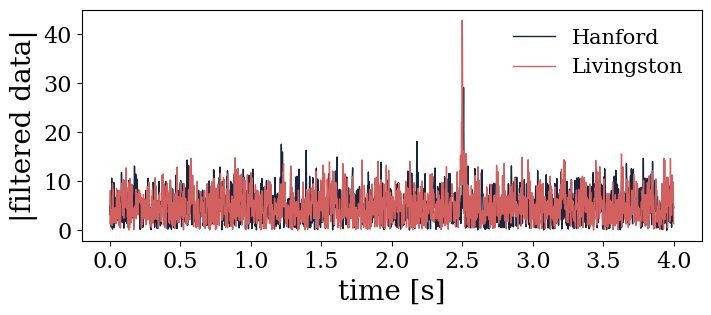

In [3]:
times, filtered = exmarg.zeta(event, data)

figstyle.apply()
plt.figure(figsize=(8, 3))
plt.plot(times, np.abs(filtered['H']), color=figstyle.NAVY, lw=1.0, label='Hanford')
plt.plot(times, np.abs(filtered['L']), color=figstyle.RED, lw=1.0, label='Livingston')
plt.xlabel('time [s]')
plt.ylabel('|filtered data|')
plt.legend(frameon=False)
plt.show()

## Load the summed tables

One file pair per filter power $u$. Loading only opens the files; the tables are read when they are used.

In [4]:
def table_files(n_max):
    files = sorted(glob.glob('%s/sumstore_n%03d_u*.lnS.npy' % (table_dir, n_max)))
    return [f.replace('.lnS.npy', '') for f in files]

tables_120 = table_files(120)
print(len(tables_120), 'filter powers')

# the arrival-time window is the whole segment: center 2 s, half width 2 s
likelihood = exmarg.SumEvaluator(event, data, tables_120, tc=2.0, dt=2.0, parallel=True)

42 filter powers


## The likelihood ratio on a grid

`likelihood.lnlam(m1, m2, chi)` returns $\ln\Lambda$ for one template. We loop over a grid of the prior box.

In [5]:
Mc_grid = np.linspace(26.5, 29.5, 13)
q_grid = np.linspace(0.6, 1.0, 9)
chi_grid = np.linspace(-0.2, 0.3, 11)

ln_lambda = np.zeros((Mc_grid.size, q_grid.size, chi_grid.size))
start = time.time()
for i, Mc in enumerate(Mc_grid):
    for j, q in enumerate(q_grid):
        for k, chi in enumerate(chi_grid):
            a, b = exmarg.mc_q_to_m1m2(Mc, q)
            ln_lambda[i, j, k] = likelihood.lnlam(a, b, chi)
seconds = time.time() - start
print('%d templates in %.0f s (%.3f s per template)' % (ln_lambda.size, seconds, seconds / ln_lambda.size))

1287 templates in 76 s (0.059 s per template)


The Bayes factor against noise is the average of $\Lambda$ over the prior, here uniform in the box
(trapezoid weights on the grid). The posterior is $\Lambda$ times the prior, normalized.

In [6]:
weights = np.gradient(Mc_grid)[:, None, None] * np.gradient(q_grid)[None, :, None] * np.gradient(chi_grid)[None, None, :]
weights = weights / weights.sum()

top = ln_lambda.max()
ln_B_ours = top + np.log(np.sum(weights * np.exp(ln_lambda - top)))
print('ln B (this work) = %.2f' % ln_B_ours)

posterior = weights * np.exp(ln_lambda - top)
posterior = posterior / posterior.sum()

ln B (this work) = 48.01


## The same segment with nested sampling

`exmarg.compare.run_bilby` gives `bilby` exactly our data, our noise curve and our prior: the same box in
$(\mathcal{M}_c, q, \chi_{\rm eff})$, uniform in volume out to the distance limit of the tables, isotropic sky and orientation,
and the arrival time anywhere in the segment. `bilby` samples the sky position, the inclination and the polarization.

In [7]:
start = time.time()
result = exmarg.compare.run_bilby(event, data, (26.5, 29.5), (0.6, 1.0), (-0.2, 0.3), nlive=300, npool=16,
                                  label='segment', outdir='bilby_runs')
print('bilby took %.0f s' % (time.time() - start))
print('ln B (nested sampling) = %.2f +- %.2f' % (result.log_bayes_factor, result.log_evidence_err))
print('ln B (this work)       = %.2f' % ln_B_ours)

22:59 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4.0, sampling_frequency=1024.0, start_time=0, frequency_domain_source_model=exmarg.compare._aligned_bbh, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomXAS', 'reference_frequency': 25.0, 'minimum_frequency': 25.0})


22:59 bilby INFO    : Loaded distance marginalisation lookup table from .distance_marginalization_lookup.npz.


22:59 bilby INFO    : Running for label 'segment', output will be saved to 'bilby_runs'


22:59 bilby INFO    : Using lal version 7.7.1


22:59 bilby INFO    : Using lal git version Branch: None;Tag: lalsuite-v7.26.16;Id: 548bc5710bea021239da56e9beff1feaae163956;;Builder: Unknown User <>;Repository status: UNCLEAN: Modified working tree


...

23:05 bilby INFO    : Sampling time: 0:06:01.302280


23:05 bilby WARNING : Result.save_to_file called with extension=True. This will default to json, and ignore the extension from the filename. This behaviour is deprecated and will be removed. 


23:05 bilby WARNING : Result.save_to_file called with extension=True. This will default to json, and ignore the extension from the filename. This behaviour is deprecated and will be removed. 


23:05 bilby INFO    : Summary of results:
nsamples: 1202
ln_noise_evidence: -4026.927
ln_evidence: -3978.621 +/-  0.203
ln_bayes_factor: 48.305 +/-  0.203



bilby took 374 s
ln B (nested sampling) = 48.31 +- 0.20
ln B (this work)       = 48.01


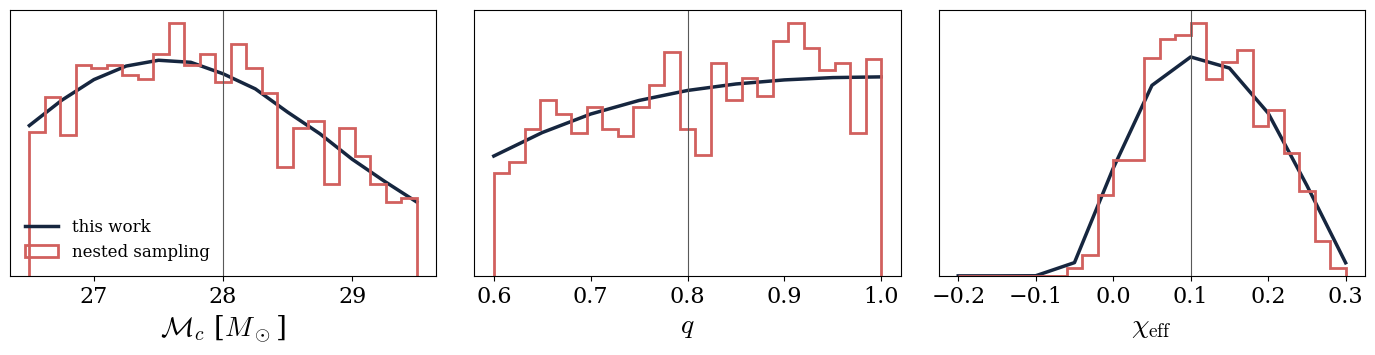

In [8]:
samples = result.posterior
pairs = [(Mc_grid, posterior.sum(axis=(1, 2)), samples['chirp_mass'], true_Mc, r'$\mathcal{M}_c$ [$M_\odot$]'),
         (q_grid, posterior.sum(axis=(0, 2)), samples['mass_ratio'], true_q, r'$q$'),
         (chi_grid, posterior.sum(axis=(0, 1)), samples['chi'], true_chi, r'$\chi_{\rm eff}$')]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (grid, marginal, sampled, truth, label) in zip(axes, pairs):
    density = marginal / np.trapezoid(marginal, grid)
    ax.plot(grid, density, color=figstyle.NAVY, lw=2.5, label='this work')
    ax.hist(sampled, bins=25, range=(grid[0], grid[-1]), density=True, histtype='step', color=figstyle.RED, lw=2.0,
            label='nested sampling')
    ax.axvline(truth, color='0.35', lw=0.8)
    ax.set_xlabel(label)
    ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.show()

## Convergence with the truncation order

The series converges once $n_{\max}$ passes $\rho_{\rm mf}^2/2$ (Sec. II). With the tables of every order we compute
$\ln\Lambda$ at the true parameters for the same merger at four distances.

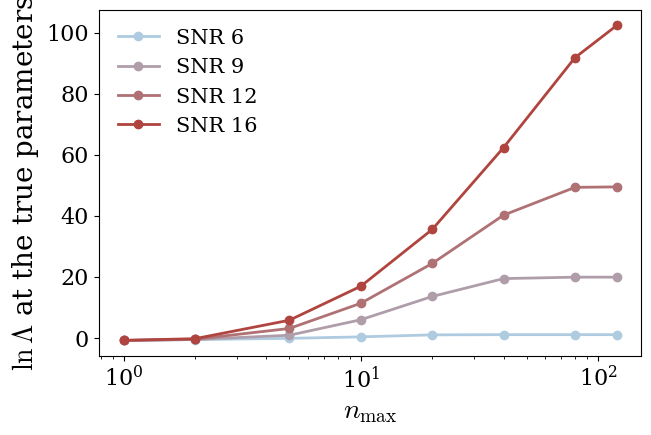

In [9]:
orders = [1, 2, 5, 10, 20, 40, 80, 120]
snrs = [6, 9, 12, 16]

plt.figure(figsize=(7, 4.5))
colors = figstyle.ramp(len(snrs))
for color, snr_k in zip(colors, snrs):
    data_k = exmarg.make_data(event, seed=12345, inject=True, phi_s=0.7, t_s=2.5, y_s=snr_k / event.rho_mf)
    values = []
    for n_max in orders:
        likelihood_n = exmarg.SumEvaluator(event, data_k, table_files(n_max), tc=2.0, dt=2.0, parallel=True)
        values.append(likelihood_n.lnlam(m1, m2, true_chi))
    plt.plot(orders, values, 'o-', color=color, lw=2, label='SNR %d' % snr_k)
plt.xscale('log')
plt.xlabel(r'$n_{\max}$')
plt.ylabel(r'$\ln\Lambda$ at the true parameters')
plt.legend(frameon=False)
plt.show()

## Figs. 16, 17 and 18 of the paper

The same convergence for the event of the paper (Fig. 16), its posterior at three orders (Fig. 17), and the comparison of the
truncated likelihood ratio with nested sampling for 252 events (Fig. 18). The values are in `../data/results`.

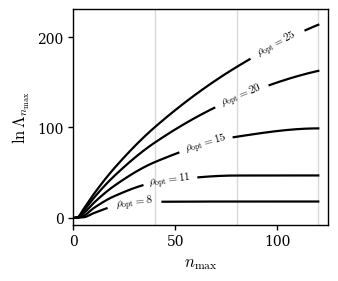

In [10]:
convergence = np.load('../data/results/convergence.npz')
figures.fig_lnlam_nmax(convergence)

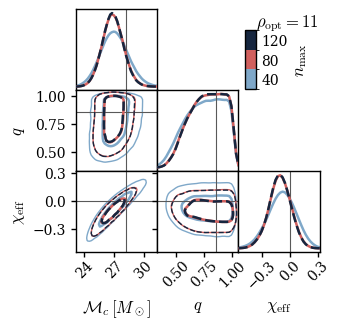

In [11]:
figures.fig_posterior_nmax(convergence)

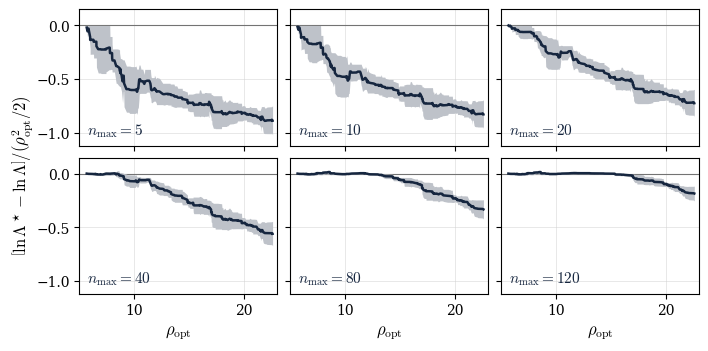

In [12]:
figures.fig_loud_ladder(np.load('../data/results/loud_ladder.npz'))

## Figs. 20 and 21 of the paper: comparison with nested sampling

For the paper we ran `bilby` with `dynesty` (2000 live points) on four segments: two in the three intrinsic parameters
(Fig. 20) and two in the source-frame primary mass and the redshift, with the distance kept as a parameter (Fig. 21).
The panels of the sky position and the orientation belong to the sampler only, since our likelihood integrates them.

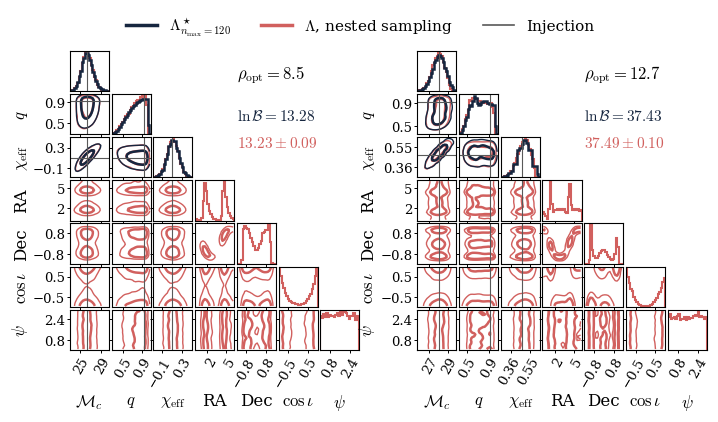

In [13]:
figures.fig_corner_3p(np.load('../data/results/ns_3p.npz'))

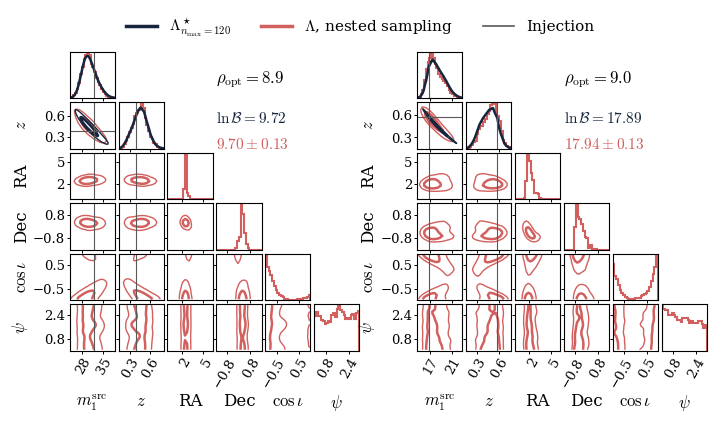

In [14]:
figures.fig_corner_2p(np.load('../data/results/ns_2p.npz'), np.load('../data/results/ns_2p_rho.npz'))